# The dataset

What the full dataset holds and how it was made: where and when the pictures were taken,
which mobs they show and how big, how much of each mob is seen, and how the labels are
checked. Every number here is computed from the exported dataset (`mobdataset make full`,
or the Hugging Face copy); no model is involved.

**Summary**
- 49,861 pictures with 177,312 labels of 88 mobs, from 4,424 places; split by place into
  39,158 train, 5,120 valid and 5,583 test pictures.
- Every area of the game: land, ocean, caves, the Nether, the End and generated structures;
  every biome; day, dusk, dawn and night; clear, rain (snow where it is cold) and thunder.
  12 % of the pictures are aerial and 4 % under water.
- 3.6 labels per picture on average; 8 % of pictures have no mob, so a model also learns
  when there is nothing.
- A median class has 1,201 labels; the rarest, 124. Most mobs are placed where the game
  would spawn them (69 %), standing, walking or running, with a random look.
- Mobs are small and far: a median box is 34 pixels tall at 26 blocks, and a tenth are
  8 pixels or less. 21 % of labels are too dark to see by brightness and contrast.
- Labels come from the game's own render of each mob, not from a projected box, so
  anything in front of a mob is already taken out of its label.

In [1]:
import os
import tomllib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as Shown
from IPython.display import display

from mobdataset.analysis import SPLITS, draw, grid, label_image, load_tables, meta, read_pictures
from mobdataset.datasets import load_dataset
from mobdataset.paths import DATA, ROOT

# The exported dataset, and the world folder it was planned in (biome map and spots).
DATASET = DATA / "datasets" / os.environ.get("NOTEBOOK_DATASET", "full")
WORLD = DATA / "worlds" / "dataset-v2"
FIGURES = ROOT / "docs" / "img"
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "savefig.bbox": "tight",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "font.size": 10,
    }
)
SPLIT_COLOURS = {"train": "#4c78a8", "valid": "#f2b134", "test": "#e45756"}
AREAS = ["land", "ocean", "caves", "nether", "end", "structures"]


def save(fig: plt.Figure, name: str) -> None:
    """Save a figure for the README (docs/img/<name>.png)."""
    fig.savefig(FIGURES / f"{name}.png")


def show(path: Path) -> None:
    """Show a saved JPEG; displaying the PIL image would also embed a far larger PNG copy."""
    display(Shown(filename=str(path)))


pictures, objects = load_tables(DATASET)
labels = objects[objects.iscrowd == 0]
cfg = load_dataset("full")
print(
    f"{len(pictures):,} pictures, {len(labels):,} labels, "
    f"{(objects.iscrowd == 1).sum():,} ignore regions"
)

49,861 pictures, 177,312 labels, 18,206 ignore regions


## 1. What was made

In [2]:
def per_split(frame: pd.DataFrame) -> pd.Series:
    return frame.groupby("split").size().reindex(SPLITS, fill_value=0)


table = pd.DataFrame(
    {
        "pictures": per_split(pictures),
        "without mobs": per_split(pictures[pictures["empty"]]),
        "labels": per_split(labels),
        "ignore regions": per_split(objects[objects.iscrowd == 1]),
        "classes": labels.groupby("split").category.nunique().reindex(SPLITS, fill_value=0),
        "places (spots)": pictures.groupby("split").spot_id.nunique().reindex(SPLITS, fill_value=0),
    }
)
table.loc["all"] = [
    len(pictures),
    pictures["empty"].sum(),
    len(labels),
    (objects.iscrowd == 1).sum(),
    labels.category.nunique(),
    pictures.spot_id.nunique(),
]
table["labels per picture"] = (table["labels"] / table["pictures"]).round(2)
display(table)

,pictures,without mobs,labels,ignore regions,classes,places (spots),labels per picture
split,,,,,,,
train,39158,3053,139289,14267,88,3480,3.56
valid,5120,435,18120,1706,88,455,3.54
test,5583,431,19903,2233,88,489,3.56
all,49861,3919,177312,18206,88,4424,3.56


**Table 1. The dataset per split.** *Ignore regions*: mobs that are there but show
essentially nothing (fewer than 4 pixels, or under 2 % of their pixels differ from the
clean plate); they are marked iscrowd so a model is neither rewarded nor punished for them.
*Places*: capture spots; every picture of a spot is in the same split.

## 2. Where

Spots were planned on a biome map of the world, read from the game without generating
terrain. The split is by place: whole 512-block tiles go to train, valid or test, and test
takes the tiles furthest from the centre, so test pictures come from terrain no training
picture shows.

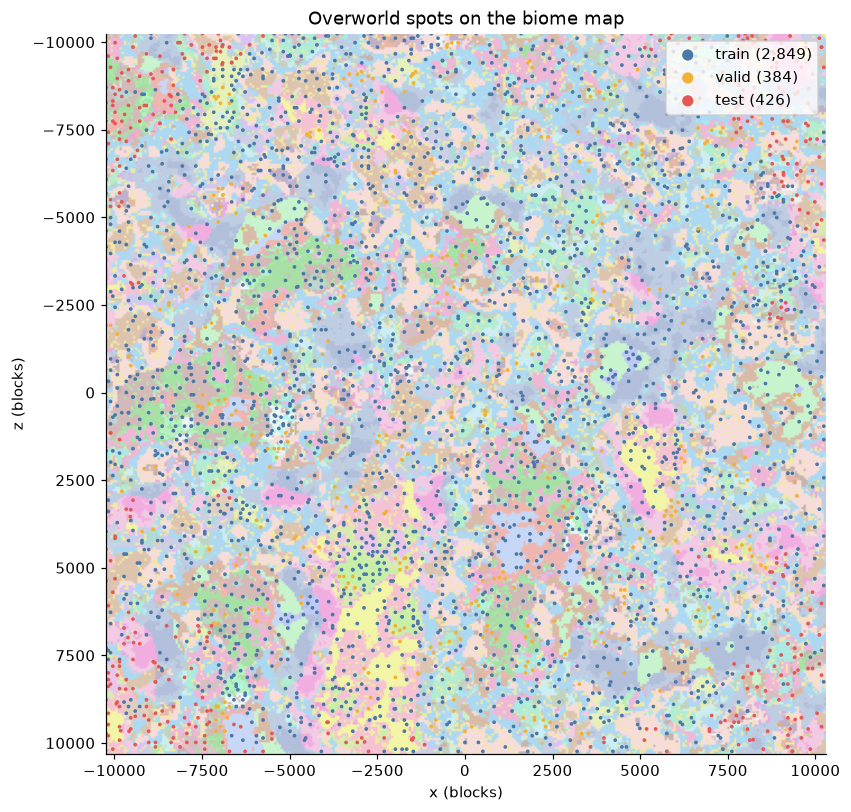

In [3]:
survey = np.load(WORLD / "survey.npz")
spots = pd.read_json(WORLD / "spots.json")
grid_ = survey["surface_grid"]
half, step = int(survey["surface_half"]), int(survey["step"])
rng = np.random.default_rng(0)
palette = rng.uniform(0.35, 0.95, size=(len(survey["surface_biomes"]), 3))
palette[list(survey["surface_biomes"]).index("ocean")] = (0.55, 0.65, 0.8)
palette[list(survey["surface_biomes"]).index("deep_ocean")] = (0.45, 0.55, 0.75)

fig, ax = plt.subplots(figsize=(8.5, 8.5))
ax.imshow(palette[grid_], extent=(-half, half + step, half + step, -half), alpha=0.55)
over = spots[spots.dimension == "overworld"]
for split, colour in SPLIT_COLOURS.items():
    s = over[over.split == split]
    ax.scatter(s.x, s.z, s=6, c=colour, label=f"{split} ({len(s):,})", edgecolors="none")
ax.set(xlabel="x (blocks)", ylabel="z (blocks)", title="Overworld spots on the biome map")
ax.grid(False)
ax.legend(loc="upper right", markerscale=3)
save(fig, "spots_map")
plt.show()

**Figure 1. Overworld capture spots on the surface biome map** (20,480 × 20,480 blocks,
one sample per 64 blocks; colours are biomes). Caves lie under the surface spots; the
Nether and the End have maps of their own. Test tiles sit at the edge of the area.

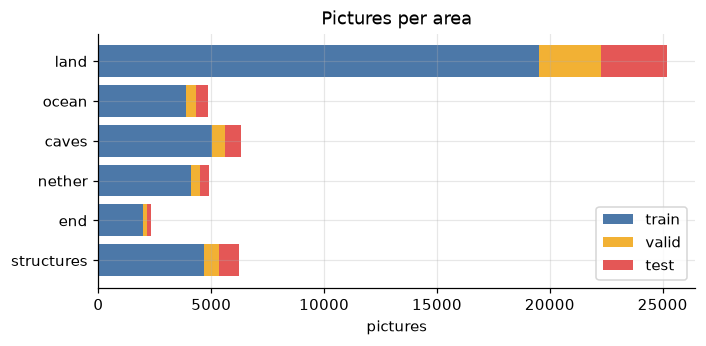

In [4]:
counts = pictures.pivot_table(index="area", columns="split", values="image_id", aggfunc="count")
counts = counts.reindex(index=[a for a in AREAS if a in counts.index], columns=SPLITS).fillna(0)
fig, ax = plt.subplots(figsize=(7, 3))
left = np.zeros(len(counts))
for split in SPLITS:
    ax.barh(counts.index, counts[split], left=left, color=SPLIT_COLOURS[split], label=split)
    left += counts[split].to_numpy()
ax.invert_yaxis()
ax.set(xlabel="pictures", title="Pictures per area")
ax.legend()
save(fig, "pictures_per_area")
plt.show()

**Figure 2. Pictures per area and split.** *Structures* are pictures at and inside
generated structures (villages, strongholds, fortresses, trial chambers, ...) and at
features (dungeons, geodes, fossils, wells, End gateways).

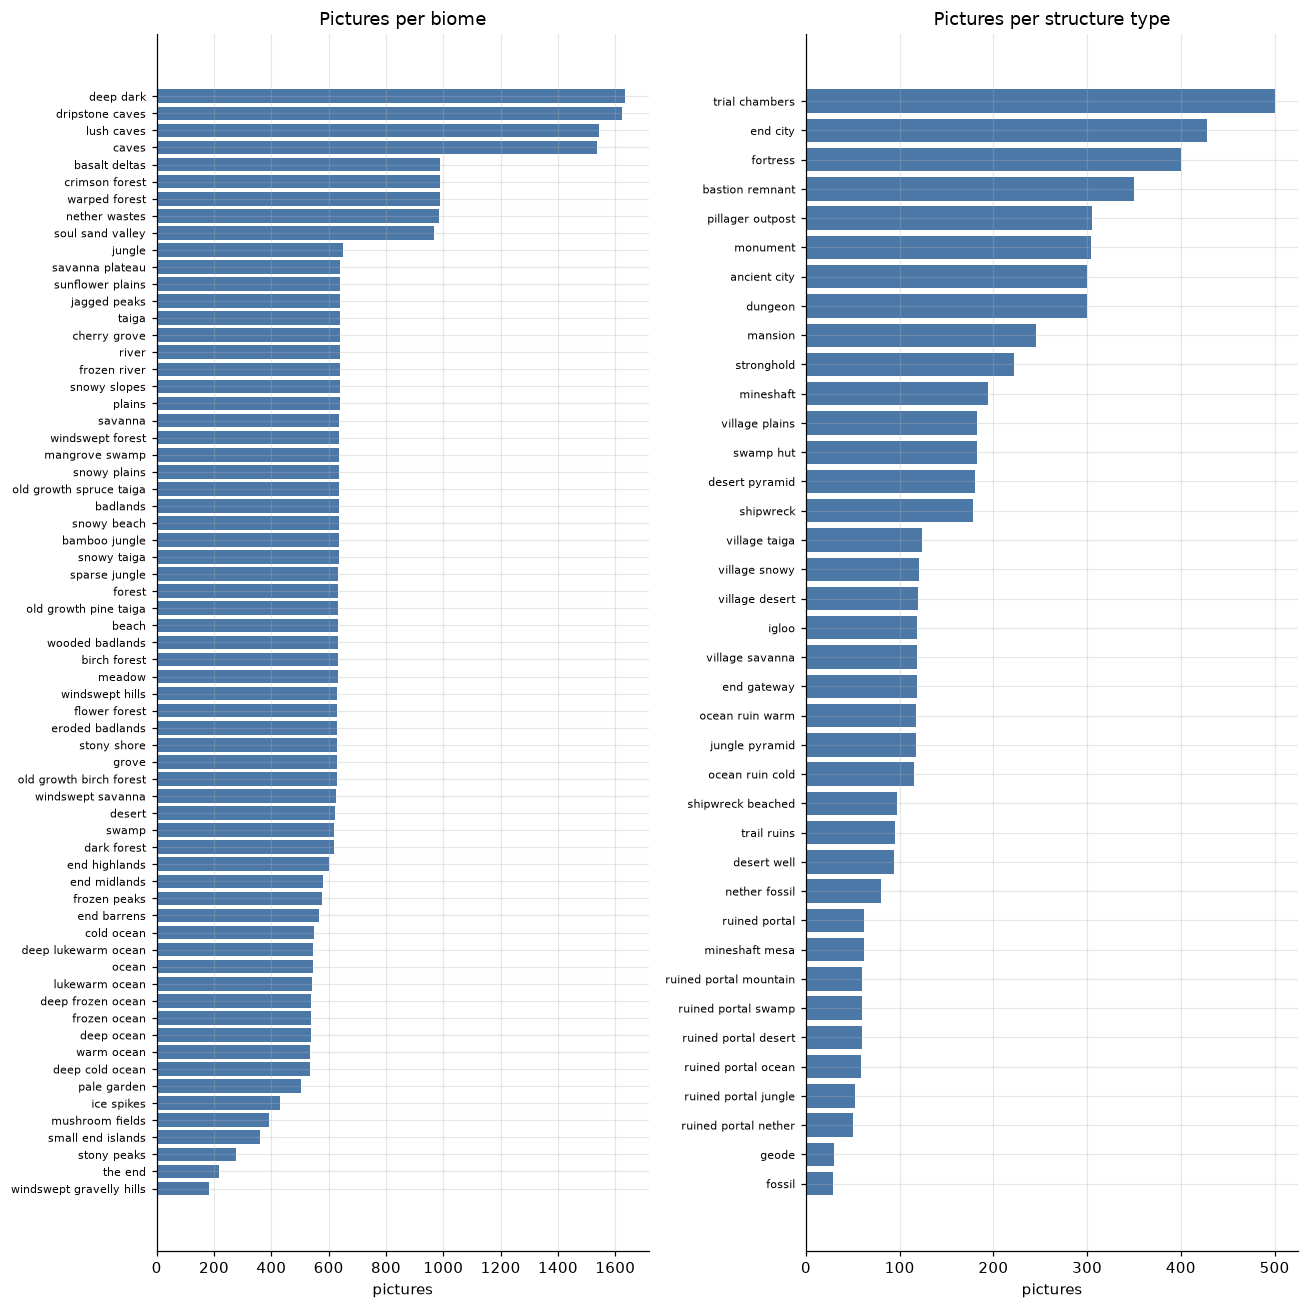

In [5]:
by_biome = pictures[pictures.area != "structures"].groupby(["area", "spot_biome"]).size()
by_structure = pictures[pictures.area == "structures"].groupby("structure").size()
fig, axes = plt.subplots(1, 2, figsize=(12, 12), gridspec_kw={"width_ratios": [1, 1]})
for ax, series, title in (
    (axes[0], by_biome.droplevel(0).sort_values(), "per biome"),
    (axes[1], by_structure.sort_values(), "per structure type"),
):
    ax.barh(series.index.str.replace("_", " "), series.to_numpy(), color="#4c78a8")
    ax.set(title=f"Pictures {title}", xlabel="pictures")
    ax.tick_params(axis="y", labelsize=7)
fig.tight_layout()
save(fig, "pictures_per_biome")
plt.show()

**Figure 3. Pictures per biome (left) and per structure type (right).** Every biome of
the game is in. The rarest (stony peaks, ice spikes, mushroom fields...) have fewer spots
than planned because the map has few places for them that are far enough apart.

## 3. When: time of day and weather

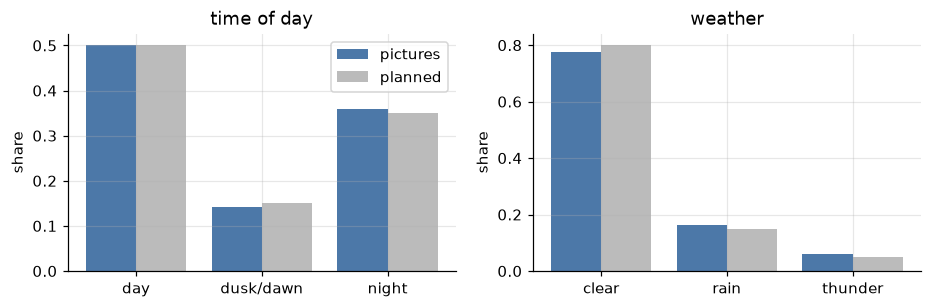

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8))
for ax, column, target in (
    (axes[0], "time", {k: v["share"] for k, v in cfg["time"].items()}),
    (axes[1], "weather", cfg["weather"]),
):
    share = pictures[column].value_counts(normalize=True).reindex(list(target), fill_value=0)
    x = np.arange(len(share))
    ax.bar(x - 0.2, share.to_numpy(), 0.4, label="pictures", color="#4c78a8")
    ax.bar(x + 0.2, list(target.values()), 0.4, label="planned", color="#bbbbbb")
    ax.set_xticks(x, [s.replace("_", "/") for s in share.index])
    ax.set(title=column.replace("time", "time of day"), ylabel="share")
axes[0].legend()
save(fig, "time_weather")
plt.show()

**Figure 4. Time of day and weather of the pictures against the plan.** Weather only
shows where the biome has it (no rain in deserts, snow in cold biomes, none underground or
in the Nether and the End), so clear comes out above its planned share.

## 4. Cameras

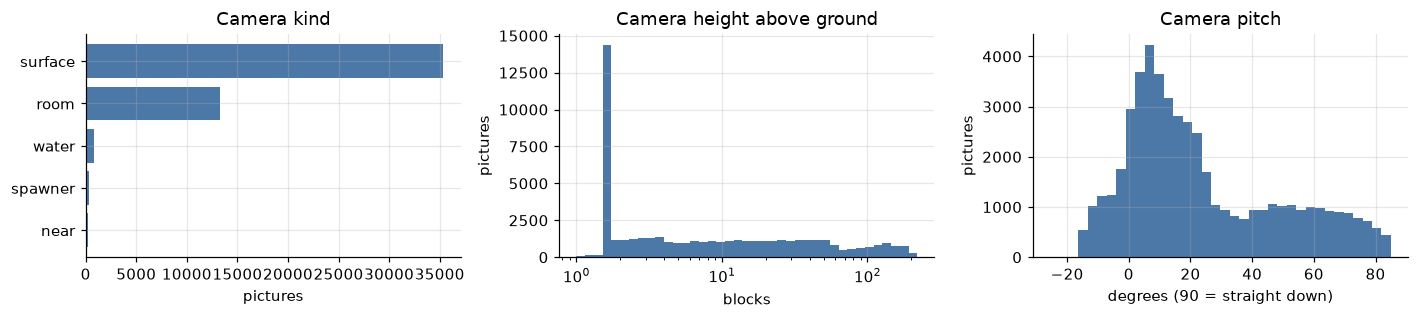

aerial 12.1%, under water 4.0%


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
kinds = pictures.camera_kind.value_counts()
axes[0].barh(kinds.index, kinds.to_numpy(), color="#4c78a8")
axes[0].invert_yaxis()
axes[0].set(title="Camera kind", xlabel="pictures")
bins = np.geomspace(1, 220, 40)
axes[1].hist(pictures.camera_height.clip(1, 220), bins=bins, color="#4c78a8")
axes[1].set(xscale="log", title="Camera height above ground", xlabel="blocks", ylabel="pictures")
axes[2].hist(pictures.pitch, bins=36, color="#4c78a8")
axes[2].set(title="Camera pitch", xlabel="degrees (90 = straight down)", ylabel="pictures")
fig.tight_layout()
save(fig, "cameras")
plt.show()
print(f"aerial {pictures.aerial.mean():.1%}, under water {pictures.underwater.mean():.1%}")

**Figure 5. Cameras.** *Surface*: above ground at a random height; *room* and *cave*:
open places the mod's probe found inside structures and underground; *aerial*: 60 to 200
blocks up, looking 40 to 85 degrees down.

## 5. Mobs

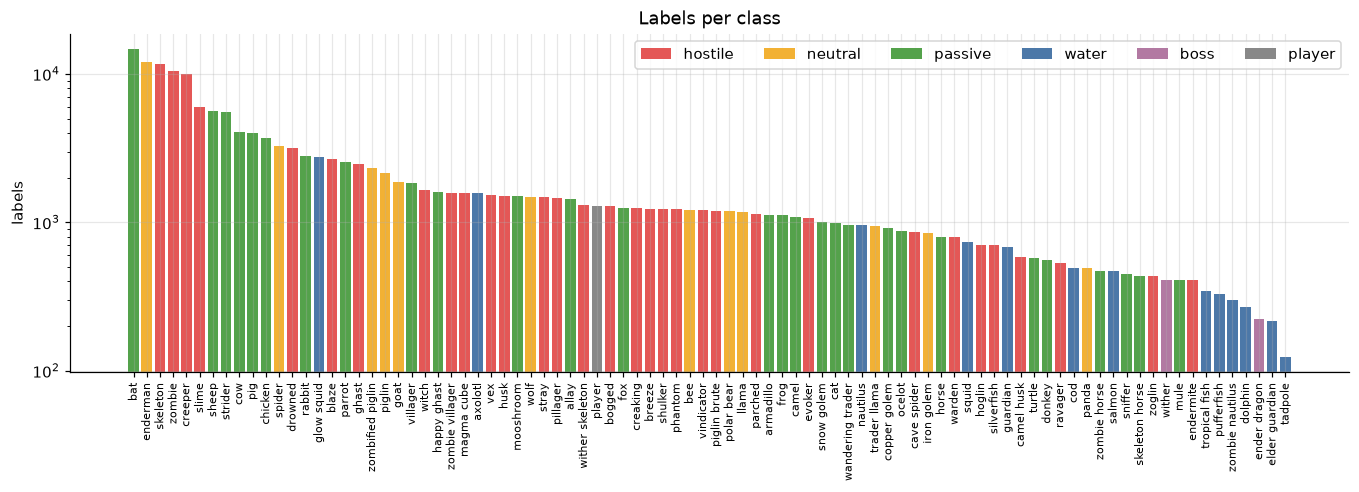

count       88.0
mean      2015.0
std       2715.0
min        124.0
25%        701.0
50%       1201.0
75%       1712.0
max      14755.0
Name: count, dtype: float64


In [8]:
groups = tomllib.loads((ROOT / "config" / "mobs" / "mobs-1.21.11.toml").read_text(encoding="utf-8"))
group_of = {m: g for g in ("hostile", "neutral", "passive", "water", "boss") for m in groups[g]}
group_of["player"] = "player"
GROUP_COLOURS = {
    "hostile": "#e45756",
    "neutral": "#f2b134",
    "passive": "#54a24b",
    "water": "#4c78a8",
    "boss": "#b279a2",
    "player": "#888888",
}
per_class = labels.category.value_counts()
fig, ax = plt.subplots(figsize=(15, 4))
ax.bar(
    per_class.index.str.replace("_", " "),
    per_class.to_numpy(),
    color=[GROUP_COLOURS[group_of.get(c, "player")] for c in per_class.index],
)
ax.set(yscale="log", ylabel="labels", title="Labels per class")
ax.tick_params(axis="x", rotation=90, labelsize=7)
for group, colour in GROUP_COLOURS.items():
    ax.bar(0, 0, color=colour, label=group)
ax.legend(ncols=6)
save(fig, "labels_per_class")
plt.show()
print(per_class.describe().round(0))

**Figure 6. Labels per class** (log scale), coloured by group. Common and native mobs
(bats underground, fish in oceans) have the most; bosses and rare mobs the fewest, but
every class has over a hundred in train.

,share of placed mobs
native to the place,0.687
still,0.447
walking,0.402
running,0.151
"with a rolled look (variant, armour, baby...)",1.000


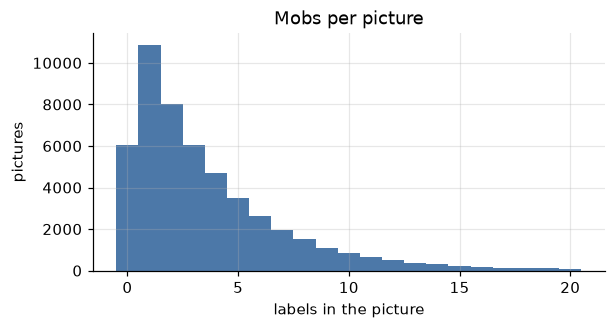

In [9]:
placed = labels[labels.placed]
mix = pd.DataFrame(
    {
        "native to the place": placed.native.mean(),
        "still": (placed.motion == "still").mean(),
        "walking": (placed.motion == "walk").mean(),
        "running": (placed.motion == "run").mean(),
        "with a rolled look (variant, armour, baby...)": placed.features.map(len).gt(0).mean(),
    },
    index=["share of placed mobs"],
).T.round(3)
display(mix)
fig, ax = plt.subplots(figsize=(6, 2.8))
per_picture = labels.groupby("image_id").size().reindex(pictures.image_id, fill_value=0)
ax.hist(per_picture, bins=np.arange(per_picture.max() + 2) - 0.5, color="#4c78a8")
ax.set(xlabel="labels in the picture", ylabel="pictures", title="Mobs per picture")
save(fig, "mobs_per_picture")
plt.show()

**Table 2. How placed mobs were chosen and posed.** *Native*: a mob that spawns there
in the game (from the game's own spawn data and structure lists); the rest are any mob that
fits the spot. **Figure 7. Labels per picture.**

## 6. Size and distance

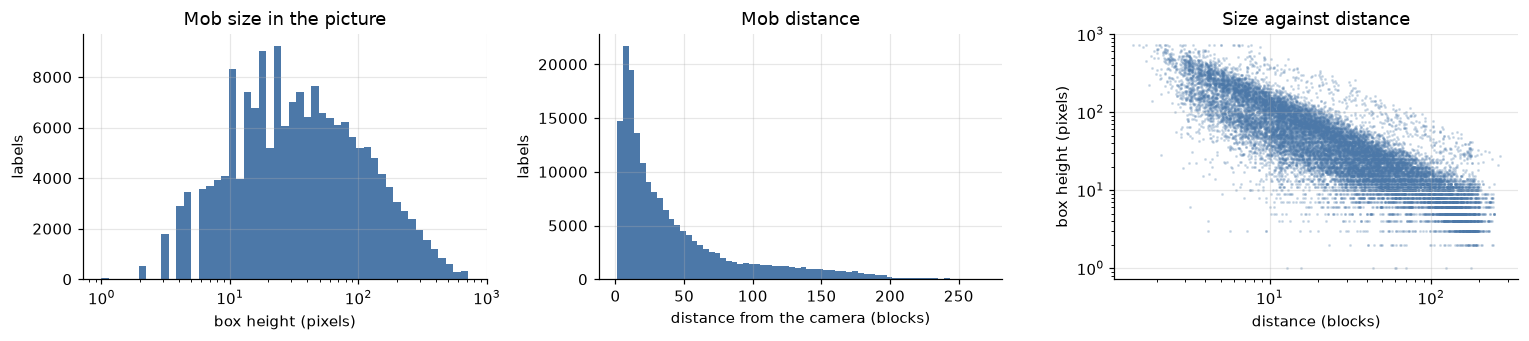

              h         w  distance
count  177312.0  177312.0  177312.0
mean       67.6      58.3      43.6
std        88.8      75.8      45.9
min         1.0       1.0       1.2
10%         8.0       7.0       5.9
50%        34.0      31.0      25.9
90%       170.0     143.0     116.0
max       720.0    1280.0     268.4


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
axes[0].hist(labels.h.clip(1, 720), bins=np.geomspace(1, 720, 50), color="#4c78a8")
axes[0].set(
    xscale="log", xlabel="box height (pixels)", ylabel="labels", title="Mob size in the picture"
)
axes[1].hist(labels.distance.clip(0, 320), bins=64, color="#4c78a8")
axes[1].set(xlabel="distance from the camera (blocks)", ylabel="labels", title="Mob distance")
sample = labels.sample(min(len(labels), 20000), random_state=0)
axes[2].scatter(sample.distance, sample.h, s=1, alpha=0.2, color="#4c78a8")
axes[2].set(
    xscale="log",
    yscale="log",
    xlabel="distance (blocks)",
    ylabel="box height (pixels)",
    title="Size against distance",
)
fig.tight_layout()
save(fig, "size_distance")
plt.show()
print(labels[["h", "w", "distance"]].describe(percentiles=[0.1, 0.5, 0.9]).round(1))

**Figure 8. How big and how far the mobs are.** Mobs are at least 6 pixels tall when
placed; distances are log-uniform up to 120 blocks with 15 % further out, up to 200 (300
for aerial pictures). Right: size falls with one over distance, spread by the size of the
mob.

## 7. How much of each mob is seen

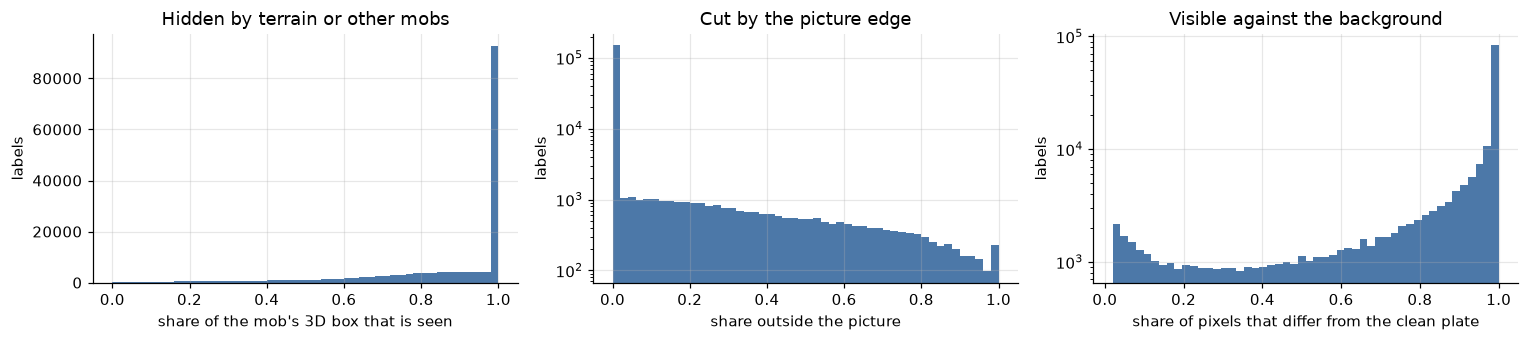

too dark to see by brightness/contrast: 21.1% of labels


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
axes[0].hist(labels.visible_share.dropna(), bins=50, color="#4c78a8")
axes[0].set(
    xlabel="share of the mob's 3D box that is seen",
    ylabel="labels",
    title="Hidden by terrain or other mobs",
)
axes[1].hist(labels.truncated.dropna(), bins=50, color="#4c78a8")
axes[1].set(
    yscale="log",
    xlabel="share outside the picture",
    ylabel="labels",
    title="Cut by the picture edge",
)
axes[2].hist(labels.visibility.dropna(), bins=50, color="#4c78a8")
axes[2].set(
    yscale="log",
    xlabel="share of pixels that differ from the clean plate",
    ylabel="labels",
    title="Visible against the background",
)
fig.tight_layout()
save(fig, "visibility")
plt.show()
print(f"too dark to see by brightness/contrast: {labels.too_dark.mean():.1%} of labels")

**Figure 9. How much of each labelled mob shows.** Left: mobs behind terrain or other mobs
keep a label for every pixel still seen. Middle: mobs partly outside the picture. Right:
against the clean plate (the same shot without the placed mobs), how much of the mob
actually changes the picture; dim, foggy and murky mobs stay labels, as players see them
too.

## 8. Pictures

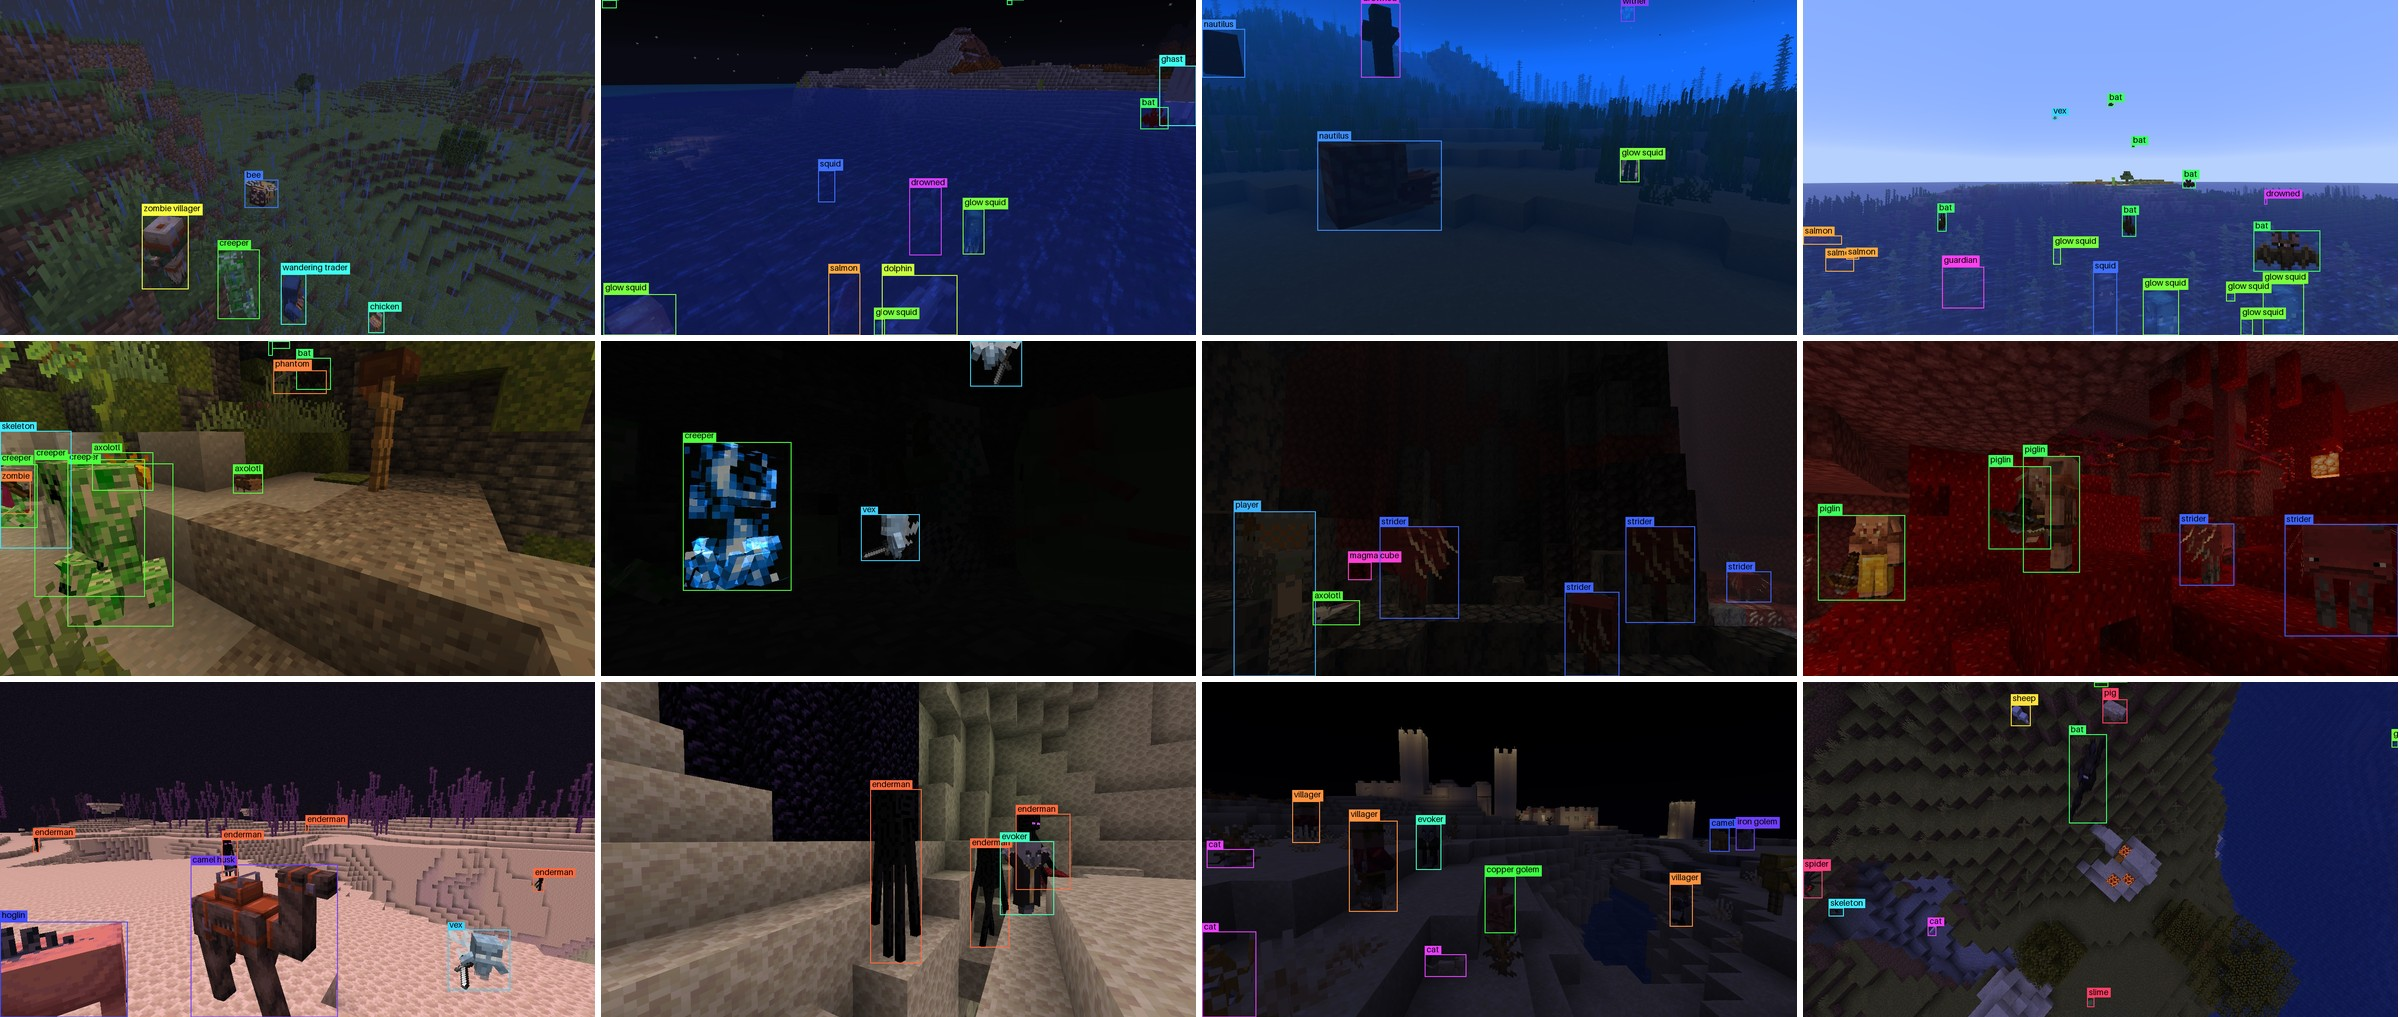

In [12]:
def pick(frame: pd.DataFrame, n: int, seed: int = 0, size: int = 0) -> list[int]:
    """Pictures with several well-seen mobs (at least `size` pixels tall), one per spot."""
    dark = labels.too_dark.fillna(False).astype(bool)
    clear = labels[(labels.visible_share > 0.5) & (labels.h >= size) & ~dark]
    seen = clear.groupby("image_id").size()
    good = frame[frame.image_id.map(seen).fillna(0) >= 3]
    good = good.groupby("spot_id").sample(1, random_state=seed)
    return good.sample(min(n, len(good)), random_state=seed).image_id.tolist()


hero_ids = []
for area in AREAS:
    hero_ids += pick(pictures[(pictures.area == area) & ~pictures.aerial], 2, size=40)
rows = read_pictures(DATASET, hero_ids)
hero_ids = [i for i in hero_ids if i in rows]
hero = grid([draw(rows[i]) for i in hero_ids if i in rows], columns=4, width=2400)
hero.save(FIGURES / "hero.jpg", quality=90)
show(FIGURES / "hero.jpg")

**Figure 10. Two pictures from each area**, with their labels.

night


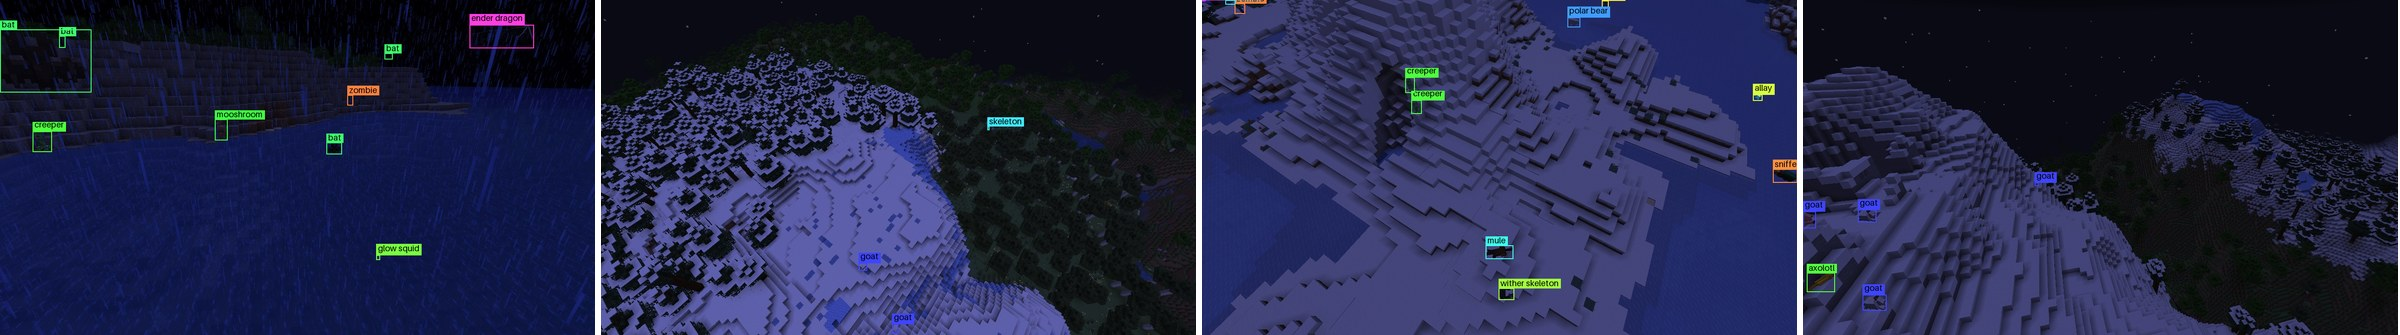

under water


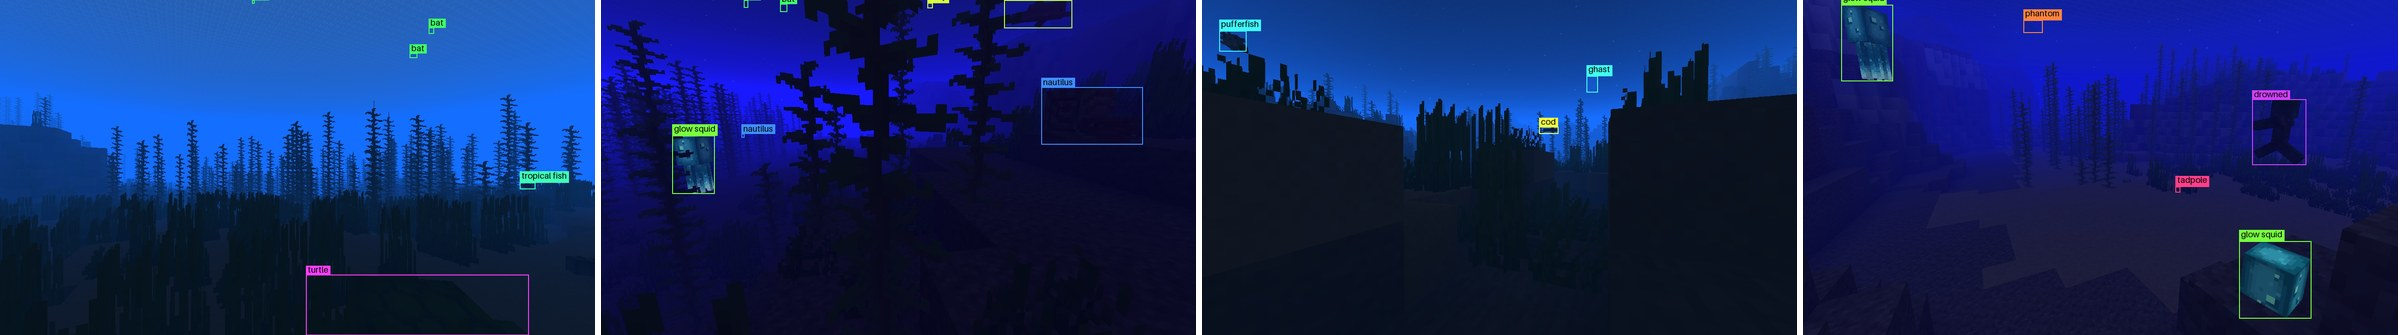

aerial


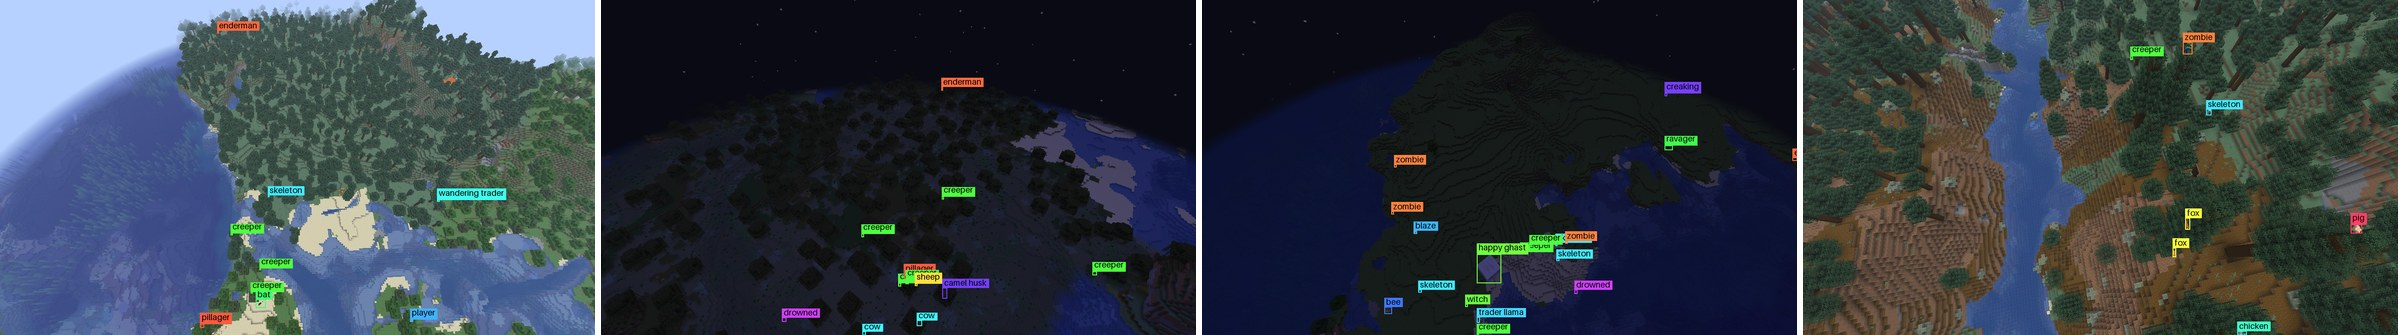

caves


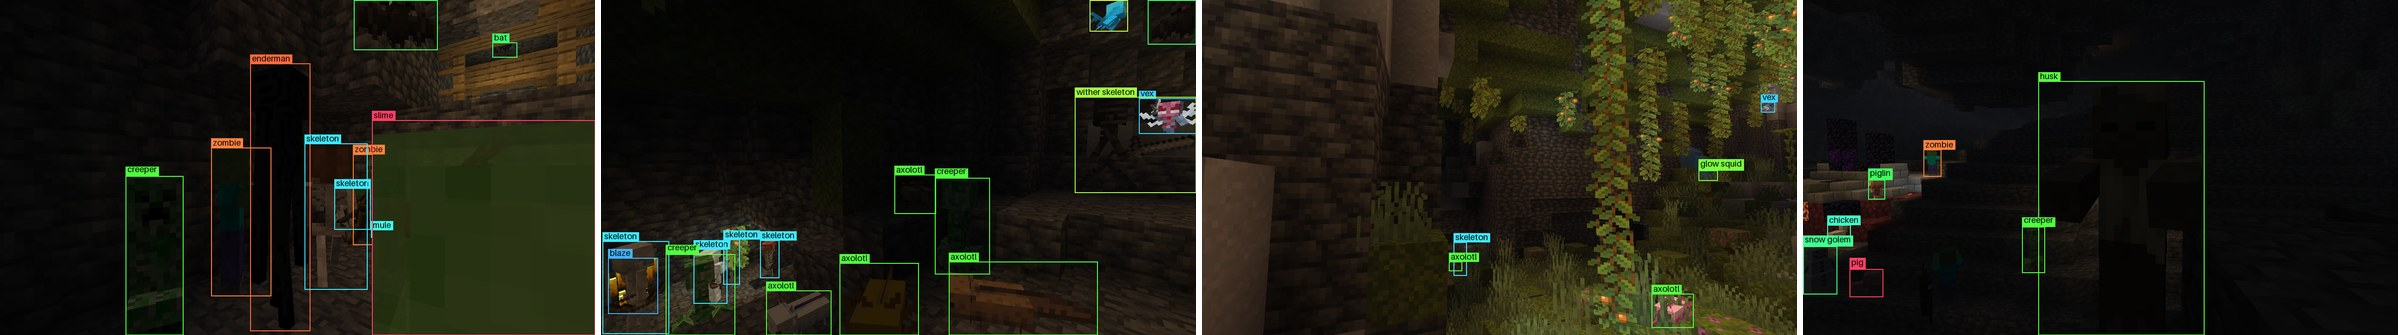

In [13]:
cases = {
    "night": pictures[(pictures.time == "night") & (pictures.area == "land")],
    "under water": pictures[pictures.underwater],
    "aerial": pictures[pictures.aerial],
    "caves": pictures[pictures.area == "caves"],
}
case_ids = {name: pick(frame, 4, seed=1) for name, frame in cases.items()}
case_rows = read_pictures(DATASET, [i for ids in case_ids.values() for i in ids])
for name, ids in case_ids.items():
    if not ids:
        continue  # a small dataset may have no pictures of a kind
    image = grid([draw(case_rows[i]) for i in ids if i in case_rows], columns=4, width=2400)
    path = FIGURES / f"cases_{name.replace(' ', '_')}.jpg"
    image.save(path, quality=88)
    print(name)
    show(path)

**Figure 11. Hard cases: night, under water, aerial and caves.**

## 9. Labels from the game itself

The mod draws a label image in the same frame as the picture: every mob's visible pixels
in its own colour, so boxes and outlines are exact and anything in front of a mob (terrain,
another mob, water) is already taken out. Right after, the same shot is taken again
without the placed mobs: the clean plate.

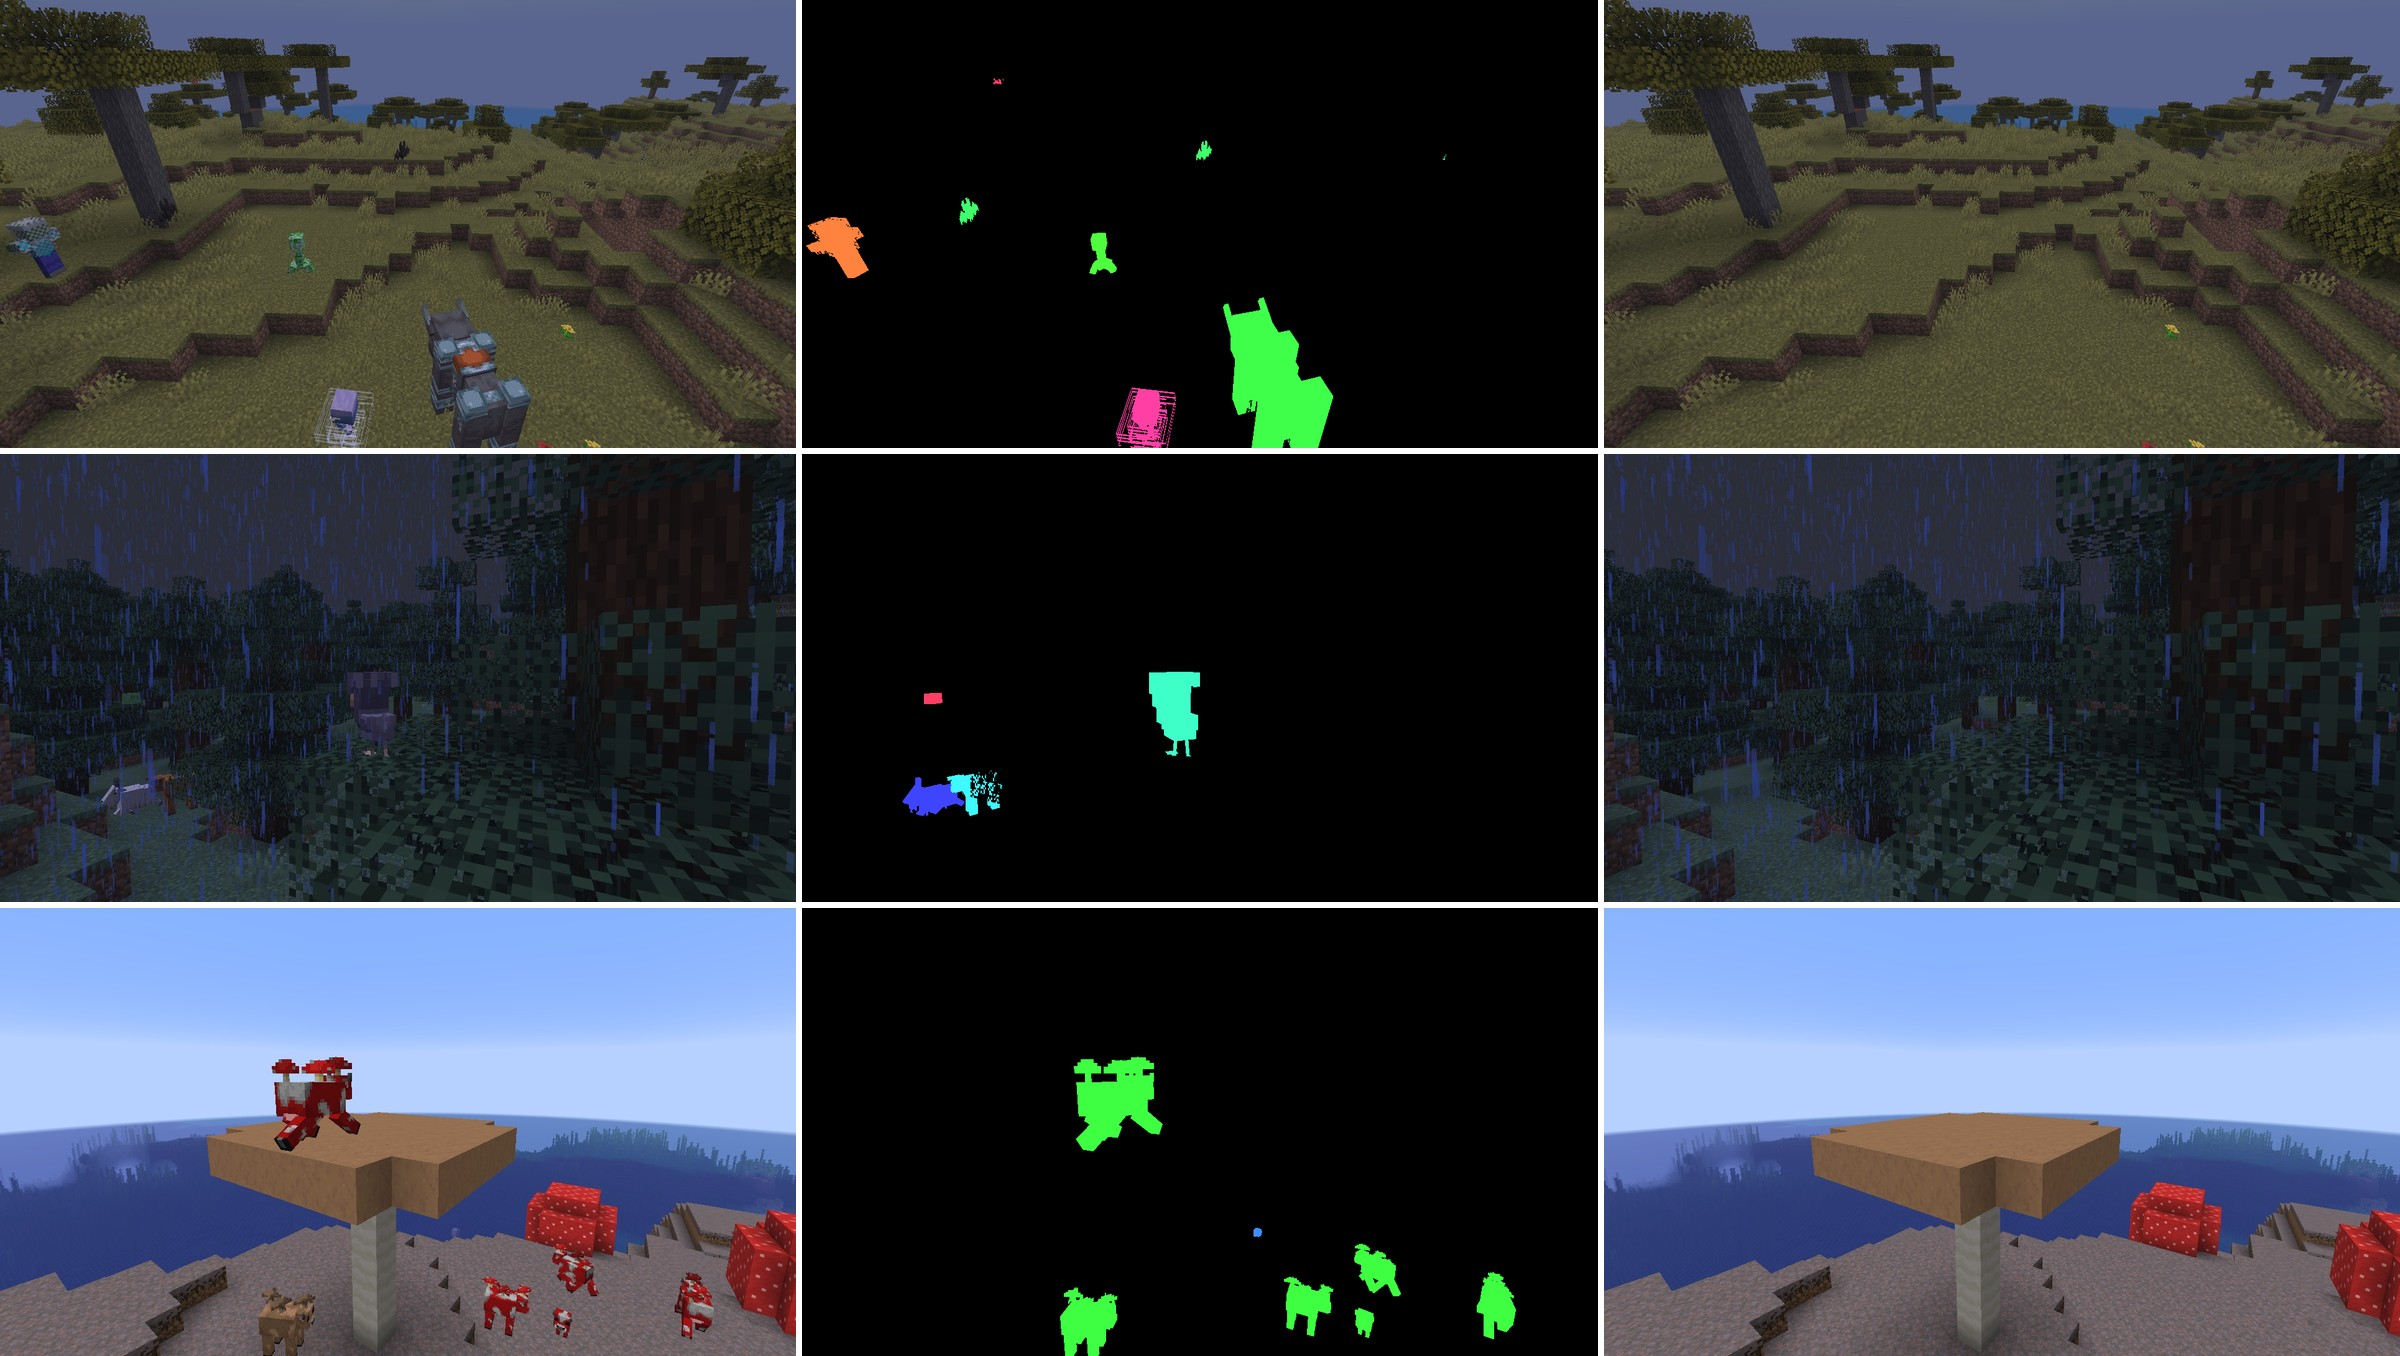

In [14]:
with_clean = pictures[pictures.has_clean_plate & ~pictures.aerial & (pictures.time == "day")]
ids = pick(with_clean, 3, seed=2, size=60)
rows = read_pictures(DATASET, ids)
panels = []
for i in ids:
    if i in rows:
        panels += [
            rows[i]["image"].convert("RGB"),
            label_image(rows[i]),
            rows[i]["clean_plate"].convert("RGB"),
        ]
if panels:
    triptych = grid(panels, columns=3, width=2400)
    triptych.save(FIGURES / "labels.jpg", quality=90)
    show(FIGURES / "labels.jpg")

**Figure 12. Picture, label image and clean plate** for three pictures. Grey in the
label image: ignore regions.

## 10. Checks on the labels

In [15]:
m = meta(DATASET)
check = pd.DataFrame(m["projection_check"]).T
display(check)
print("bytes per picture:", m["bytes_per_picture"])

,mobs,median_iou,inside_share,median_edge_px
all,164419.0,0.649,0.514,2.2
labelled,149274.0,0.653,0.513,2.2
labelled_mostly_seen,136942.0,0.670,0.486,2.0
box_shaped,1086.0,0.954,1.000,0.3


bytes per picture: {'jpeg': 231534, 'clean_jpeg': 211857, 'parquet': 444465}


**Table 3. Projected 3D boxes against the visible boxes**, for mobs not cut by the picture
edge. *box_shaped*: shulkers, whose model fills their box exactly, so their IoU checks the
projection itself (the others are lower because a mob's model is smaller than its box).
Before the full run, labels were also checked against clean plates on 3,000 pictures
(`mobdataset check clean-plates`): a median of 99 % of label pixels change the picture,
and every label under 80 % was a mob that really cannot be seen (fog, dark water).